# Draft experiment: does changing K improve fraud triage?

**Exploratory work only.** The official Phase 1 notebooks, results, report and presentation are unchanged.

We change only the number of Gaussian components. We compare **K = 4, 6, 8, 12, 16, 24, 32**. K=8 uses the existing fitted submission model. All other candidates use the same legitimate training rows, prepared features and fitting settings.

**Question:** Does a larger or smaller K find more fraud, reduce false alerts, or improve ranking on the existing split?

**Evaluation rules fixed before this run:**
- Fit only legitimate training inputs from notebook 03. Keep scaling and splits unchanged.
- Use diagonal covariance, three initializations, up to 200 iterations, regularization 1e-6, seed 42.
- Select the density model using the smallest training BIC among converged candidates.
- For each candidate, derive its own threshold from legitimate validation scores at the same **0.5% FPR budget**. The numerical threshold must change when its model changes.
- Report validation and test trapezoidal PR AUC, recall, precision, actual FPR, and precision@100.
- Compare every candidate descriptively; do not replace the submission model automatically.

**Why exploratory?** We have already inspected this test period. Selecting a new model because its test results look better would reuse test information. These comparisons can guide further work, but cannot establish an unbiased improvement on unseen data. Validation also has only 57 frauds; test has 74.

**Reads:** `data/processed/features.npz`, `models/gmm_models.joblib`, `results/summary.json`.

**Writes only draft outputs:** `output/drafts/gmm_k_sweep/` and this draft notebook. All experiment code is visible below.

## 1. Setup
The folder check lets this notebook run from the project root, `notebooks/`, or `notebooks/drafts/`. Two numerical threads keep the fitting workload controlled.

In [1]:
from pathlib import Path
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Image
from sklearn.mixture import GaussianMixture
from sklearn.metrics import precision_recall_curve, auc, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "CSAI_Project_Instructions_Phase_1_and_Phase_2.pdf").exists())
ROOT = PROJECT / "phase1"
os.chdir(ROOT)
DRAFT = Path("output/drafts/gmm_k_sweep")
DRAFT.mkdir(parents=True, exist_ok=True)
component_counts = [4, 6, 8, 12, 16, 24, 32]
budget = 0.005

## 2. Load exactly the same inputs
`X_train` contains only legitimate, already-scaled inputs. Validation and test retain both classes. We reuse the existing K=8 model so it is an exact reference to the submission, rather than a different fit. We do not fit the scaler again.

In [2]:
arrays = np.load("data/processed/features.npz", allow_pickle=False)
X_train = arrays["X_train"]
X_validation = arrays["X_validation"]
X_test = arrays["X_test"]
y_validation = arrays["y_validation"]
y_test = arrays["y_test"]
baseline = joblib.load("models/gmm_models.joblib")["selected_gmm"]
official = json.loads(Path("results/summary.json").read_text())
assert baseline.n_components == 8
assert X_train.shape == (169893, 29)
assert int(y_validation.sum()) == 57 and int(y_test.sum()) == 74
print("Training:", X_train.shape, "Validation:", X_validation.shape, "Test:", X_test.shape)
print("Frauds: validation", int(y_validation.sum()), "; test", int(y_test.sum()))

Training: (169893, 29) Validation: (56745, 29) Test: (56746, 29)
Frauds: validation 57 ; test 74


## 3. Fit the candidate models
Only K changes. `fit` runs EM inside scikit-learn. K=8 is loaded, so its fit time is not measured in this experiment. Every other fit receives three initializations. We record convergence rather than silently accepting an unfinished fit. A partial CSV is updated after each candidate so progress remains visible.

In [3]:
models = {}
training_rows = []
with threadpool_limits(limits=2):
    for k in component_counts:
        start = time.perf_counter()
        if k == 8:
            candidate = baseline
            fit_seconds = np.nan
            warning_text = ""
        else:
            candidate = GaussianMixture(n_components=k, covariance_type="diag",
                n_init=3, max_iter=200, reg_covar=1e-6, random_state=42)
            with warnings.catch_warnings(record=True) as recorded_warnings:
                warnings.simplefilter("always", ConvergenceWarning)
                candidate.fit(X_train)
            fit_seconds = time.perf_counter() - start
            warning_text = "; ".join(str(item.message) for item in recorded_warnings)
        models[k] = candidate
        joblib.dump(models, "models/draft_gmm_candidates.joblib")
        training_rows.append({"K": k, "AIC": candidate.aic(X_train),
            "BIC": candidate.bic(X_train), "Converged": bool(candidate.converged_),
            "Iterations": int(candidate.n_iter_), "Fit seconds": fit_seconds,
            "Source": "existing submission model" if k == 8 else "new fit",
            "Warnings": warning_text})
        pd.DataFrame(training_rows).to_csv(DRAFT / "training_comparison.csv", index=False)
        print("Finished K =", k, "Converged:", candidate.converged_,
            "Iterations:", candidate.n_iter_, flush=True)
training_table = pd.DataFrame(training_rows)
display(training_table.round(4))
converged_table = training_table[training_table["Converged"]]
assert len(converged_table) > 0
bic_k = int(converged_table.loc[converged_table["BIC"].idxmin(), "K"])
print("Smallest training BIC within the expanded grid: K =", bic_k)

Finished K = 4 Converged: True Iterations: 32
Finished K = 6 Converged: True Iterations: 28
Finished K = 8 Converged: True Iterations: 35
Finished K = 12 Converged: True Iterations: 65
Finished K = 16 Converged: True Iterations: 67
Finished K = 24 Converged: True Iterations: 54
Finished K = 32 Converged: True Iterations: 41
Smallest training BIC within the expanded grid: K = 32


,K,AIC,BIC,Converged,Iterations,Fit seconds,Source,Warnings
0,4,1.089440e+07,1.089676e+07,True,32,6.2106,new fit,
1,6,1.058643e+07,1.058997e+07,True,28,7.1702,new fit,
2,8,1.014018e+07,1.014492e+07,True,35,NaN,existing submission model,
3,12,9.656397e+06,9.663497e+06,True,65,9.1653,new fit,
4,16,9.251201e+06,9.260672e+06,True,67,12.2393,new fit,
5,24,8.911283e+06,8.925494e+06,True,54,23.2813,new fit,
6,32,8.556538e+06,8.575489e+06,True,41,20.3293,new fit,


## 4. Evaluate each converged model using the same rules
The validation threshold is the 99.5th percentile of that model's legitimate validation scores. `score > cutoff` creates an alert. Test outcomes never change this cutoff.

For both periods:
- **PR AUC:** trapezoidal area under the precision-recall curve.
- **Fraud found / missed:** compare alerts against correct labels.
- **Precision:** fraud found / all alerts.
- **Recall:** fraud found / all actual fraud.
- **FPR:** legitimate alerts / all legitimate transactions.
- **Precision@100:** fraud among the 100 highest scores / 100.

We report actual test FPR because equal validation budgets need not produce equal test false-alert rates. A higher recall with a much larger test FPR is a trade-off, not a free improvement.

In [4]:
evaluation_rows = []
curves = {}
with threadpool_limits(limits=2):
    for k in component_counts:
        candidate = models[k]
        if not candidate.converged_:
            print("Skipping non-converged K =", k)
            continue
        validation_scores = -candidate.score_samples(X_validation)
        normal_scores = validation_scores[y_validation == 0]
        cutoff = float(np.percentile(normal_scores, 100 * (1 - budget), method="higher"))
        assert np.mean(normal_scores > cutoff) <= budget
        test_scores = -candidate.score_samples(X_test)
        row = {"K": k, "Threshold": cutoff}
        for period, labels, scores in [("Validation", y_validation, validation_scores),
                                       ("Test", y_test, test_scores)]:
            assert np.isfinite(scores).all()
            precision, recall, _ = precision_recall_curve(labels, scores)
            curves[(k, period)] = (recall, precision)
            alerts = scores > cutoff
            tn, fp, fn, tp = confusion_matrix(labels, alerts, labels=[0, 1]).ravel()
            order = np.argsort(-scores, kind="stable")
            top_100_frauds = int(labels[order[:100]].sum())
            row[period + " PR AUC"] = float(auc(recall, precision))
            row[period + " fraud found"] = int(tp)
            row[period + " fraud missed"] = int(fn)
            row[period + " false alerts"] = int(fp)
            row[period + " alerts"] = int(tp + fp)
            row[period + " recall (%)"] = 100 * tp / (tp + fn)
            row[period + " precision (%)"] = 100 * tp / (tp + fp) if tp + fp else 0.0
            row[period + " FPR (%)"] = 100 * fp / (fp + tn)
            row[period + " top 100 frauds"] = top_100_frauds
            row[period + " precision@100 (%)"] = float(top_100_frauds)
            assert tn + fp + fn + tp == len(labels)
        evaluation_rows.append(row)
        pd.DataFrame(evaluation_rows).to_csv(DRAFT / "evaluation_comparison.csv", index=False)
comparison = pd.DataFrame(evaluation_rows)
comparison = comparison.merge(training_table[["K", "BIC", "Converged", "Iterations"]], on="K")
comparison.to_csv(DRAFT / "comparison.csv", index=False)
display(comparison[["K", "Validation PR AUC", "Test PR AUC", "Test fraud found",
    "Test fraud missed", "Test false alerts", "Test FPR (%)", "Test precision@100 (%)"]].round(4))
reference = comparison[comparison["K"] == 8].iloc[0]
assert np.isclose(reference["Test PR AUC"], official["PR_AUC"])
assert int(reference["Test fraud found"]) == official["TP"]
assert int(reference["Test false alerts"]) == official["FP"]
assert np.isclose(reference["Test precision@100 (%)"], 100 * official["precision_at_100"])
print("K=8 exactly reproduces the submission metrics.")

K=8 exactly reproduces the submission metrics.


,K,Validation PR AUC,Test PR AUC,Test fraud found,Test fraud missed,Test false alerts,Test FPR (%),Test precision@100 (%)
0,4,0.0571,0.1249,34,40,172,0.3035,25.0
1,6,0.0570,0.1248,34,40,171,0.3017,25.0
2,8,0.0718,0.1496,37,37,172,0.3035,29.0
3,12,0.0686,0.1431,36,38,174,0.3070,27.0
4,16,0.0735,0.1448,38,36,179,0.3159,30.0
5,24,0.0967,0.1782,44,30,186,0.3282,31.0
6,32,0.1535,0.2481,45,29,195,0.3441,34.0


## 5. Read the comparison charts
The BIC chart concerns legitimate training fit. The PR chart concerns ranking fraud. Their preferred K can differ. The default-policy chart shows both fraud found and false alerts so recall improvements cannot hide extra review work. The capacity chart compares the same 100-review budget for every model.

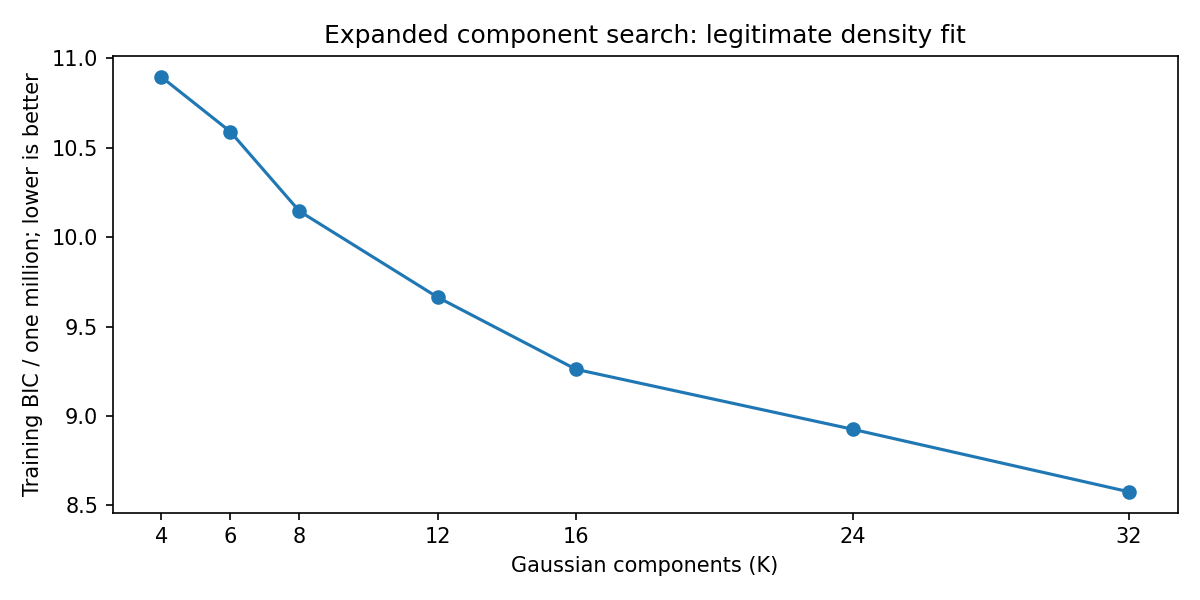

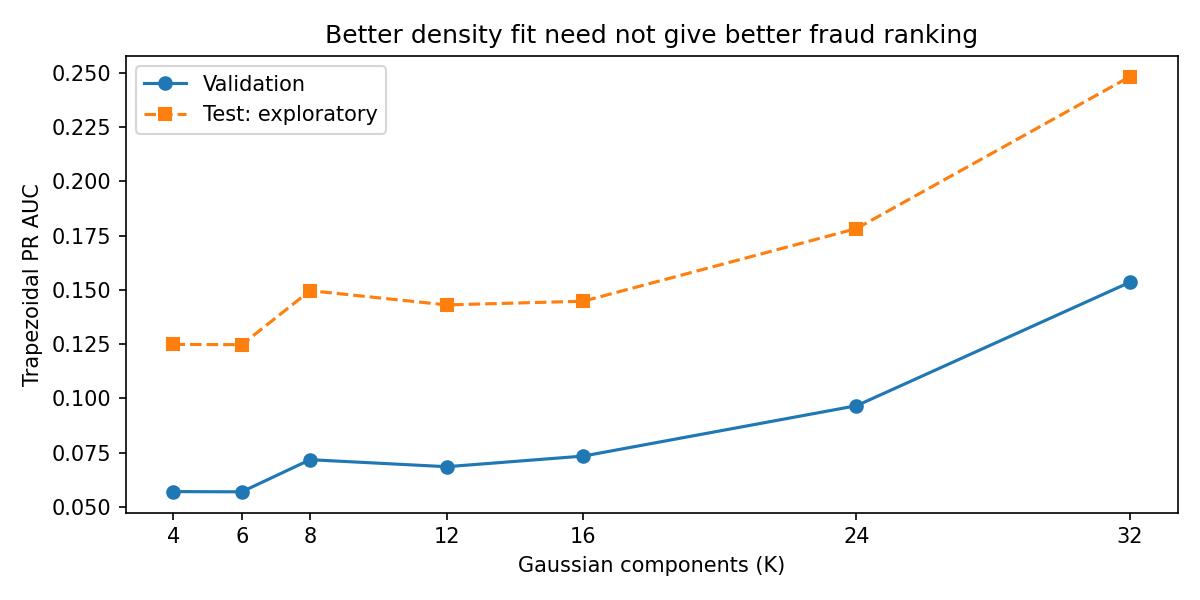

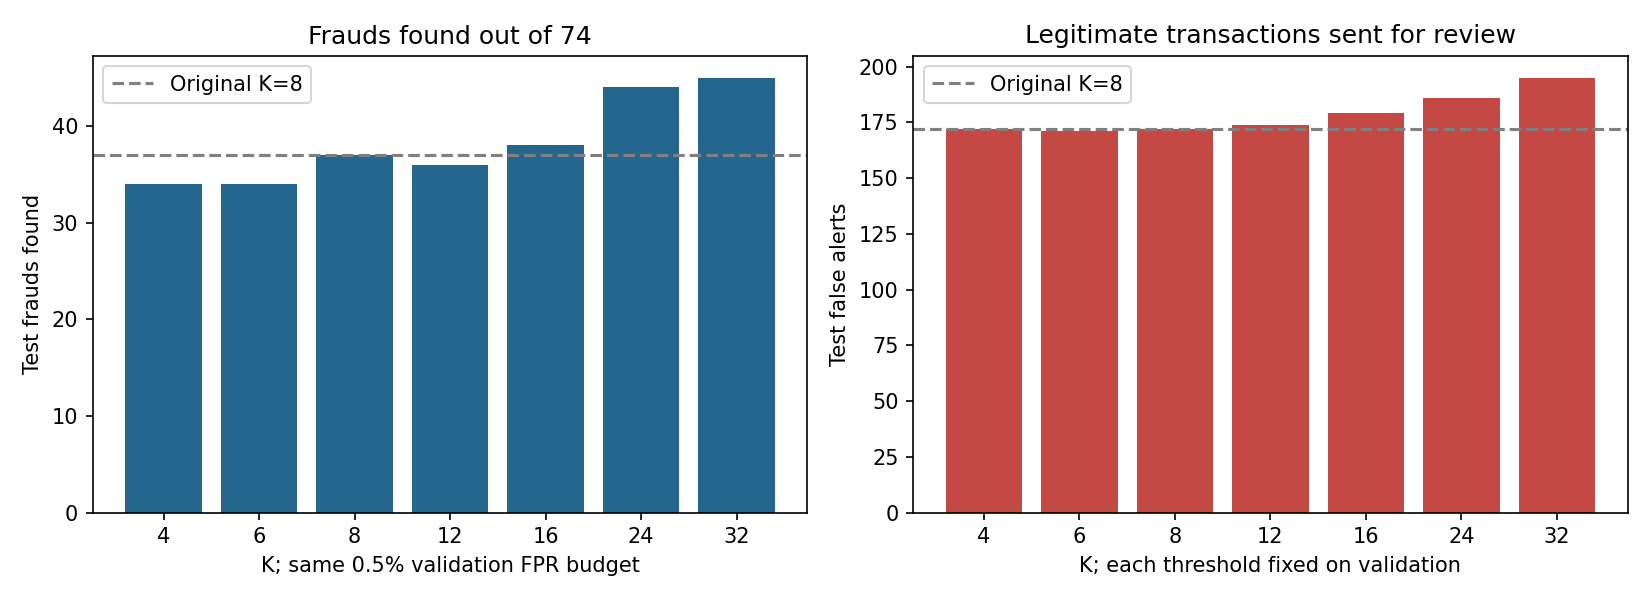

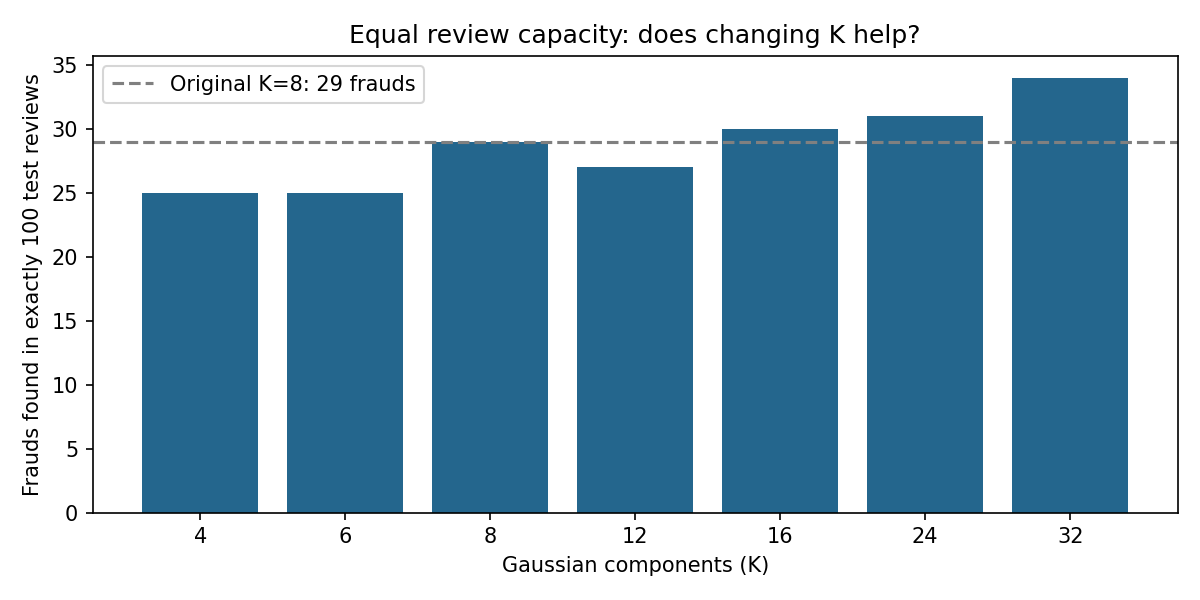

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(training_table["K"], training_table["BIC"] / 1_000_000, "o-")
plt.xticks(component_counts)
plt.xlabel("Gaussian components (K)")
plt.ylabel("Training BIC / one million; lower is better")
plt.title("Expanded component search: legitimate density fit")
plt.tight_layout()
plt.savefig(DRAFT / "01_training_bic.png", dpi=150)
display(Image(filename=str(DRAFT / "01_training_bic.png"), width=900))
plt.close()

plt.figure(figsize=(8, 4))
plt.plot(comparison["K"], comparison["Validation PR AUC"], "o-", label="Validation")
plt.plot(comparison["K"], comparison["Test PR AUC"], "s--", label="Test: exploratory")
plt.xticks(component_counts)
plt.xlabel("Gaussian components (K)")
plt.ylabel("Trapezoidal PR AUC")
plt.title("Better density fit need not give better fraud ranking")
plt.legend()
plt.tight_layout()
plt.savefig(DRAFT / "02_pr_auc.png", dpi=150)
display(Image(filename=str(DRAFT / "02_pr_auc.png"), width=900))
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(comparison["K"].astype(str), comparison["Test fraud found"], color="#24668d")
axes[0].axhline(official["TP"], linestyle="--", color="gray", label="Original K=8")
axes[0].set_title("Frauds found out of 74")
axes[0].set_xlabel("K; same 0.5% validation FPR budget")
axes[0].set_ylabel("Test frauds found")
axes[0].legend()
axes[1].bar(comparison["K"].astype(str), comparison["Test false alerts"], color="#c44945")
axes[1].axhline(official["FP"], linestyle="--", color="gray", label="Original K=8")
axes[1].set_title("Legitimate transactions sent for review")
axes[1].set_xlabel("K; each threshold fixed on validation")
axes[1].set_ylabel("Test false alerts")
axes[1].legend()
plt.tight_layout()
plt.savefig(DRAFT / "03_default_policy.png", dpi=150)
display(Image(filename=str(DRAFT / "03_default_policy.png"), width=900))
plt.close()

plt.figure(figsize=(8, 4))
plt.bar(comparison["K"].astype(str), comparison["Test top 100 frauds"], color="#24668d")
plt.axhline(29, linestyle="--", color="gray", label="Original K=8: 29 frauds")
plt.xlabel("Gaussian components (K)")
plt.ylabel("Frauds found in exactly 100 test reviews")
plt.title("Equal review capacity: does changing K help?")
plt.legend()
plt.tight_layout()
plt.savefig(DRAFT / "04_top_100.png", dpi=150)
display(Image(filename=str(DRAFT / "04_top_100.png"), width=900))
plt.close()

## 6. Compare the original model with the training-BIC selection
This comparison follows the same BIC rule used in notebook 04, with a larger candidate list. The test curve is descriptive because this period was already examined. No model here is promoted to the official submission automatically.

Selected by training BIC:
All results remain draft outputs. No submission files were replaced.


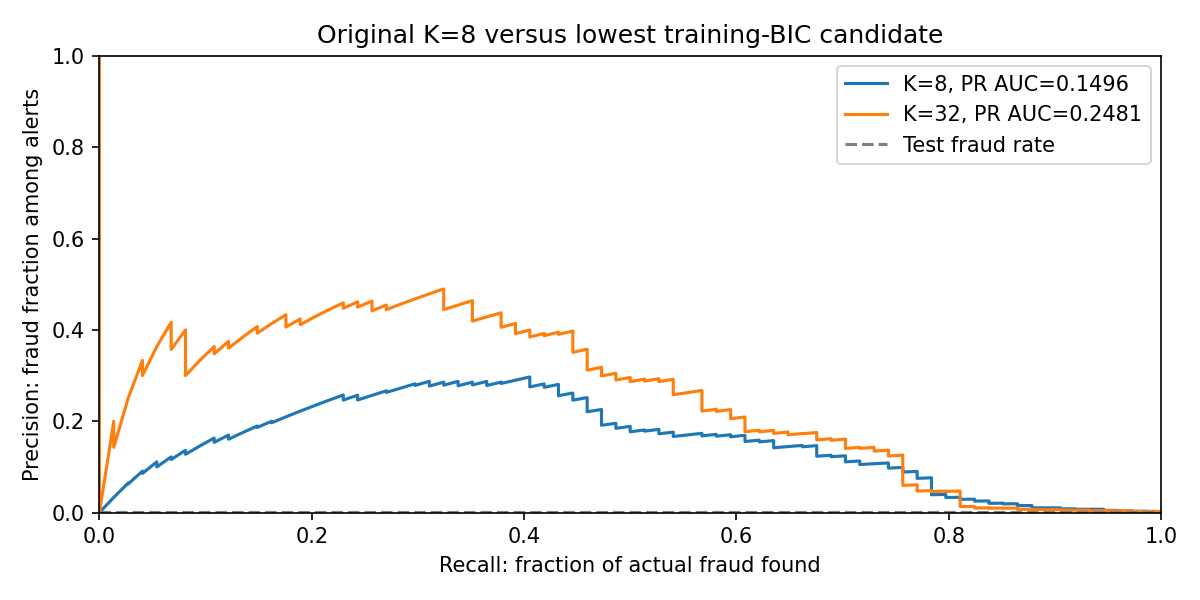

,K,BIC,Validation PR AUC,Test PR AUC,Test fraud found,Test fraud missed,Test false alerts,Test precision@100 (%)
6,32,8.575489e+06,0.1535,0.2481,45,29,195,34.0


In [6]:
plt.figure(figsize=(8, 4))
for k in sorted(set([8, bic_k])):
    recall, precision = curves[(k, "Test")]
    area = float(comparison.loc[comparison["K"] == k, "Test PR AUC"].iloc[0])
    plt.plot(recall, precision, label=f"K={k}, PR AUC={area:.4f}")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label="Test fraud rate")
plt.xlabel("Recall: fraction of actual fraud found")
plt.ylabel("Precision: fraud fraction among alerts")
plt.title("Original K=8 versus lowest training-BIC candidate")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig(DRAFT / "05_pr_curve.png", dpi=150)
display(Image(filename=str(DRAFT / "05_pr_curve.png"), width=900))
plt.close()
selected = comparison[comparison["K"] == bic_k]
print("Selected by training BIC:")
display(selected[["K", "BIC", "Validation PR AUC", "Test PR AUC", "Test fraud found",
    "Test fraud missed", "Test false alerts", "Test precision@100 (%)"]].round(4))
print("All results remain draft outputs. No submission files were replaced.")

## How to interpret this experiment

- A model can improve PR AUC without improving recall at the chosen cutoff, or vice versa.
- Compare fraud found **together with** false alerts and total reviews.
- Precision@100 compares the same review capacity across candidates.
- A minimum BIC at the largest tested K still leaves the search boundary unresolved.
- A good result on this already-inspected test set is exploratory evidence, not a fresh held-out confirmation.
- Before any promotion, keep a model-selection rule separate from final evaluation and use an untouched later dataset when available.

## Measured findings: increasing K helped on this split

| K | Test PR AUC | Fraud found / 74 | Fraud missed | False alerts | Fraud in top 100 |
|---:|---:|---:|---:|---:|---:|
| 4 | 0.1249 | 34 | 40 | 172 | 25 |
| 6 | 0.1248 | 34 | 40 | 171 | 25 |
| 8 | 0.1496 | 37 | 37 | 172 | 29 |
| 12 | 0.1431 | 36 | 38 | 174 | 27 |
| 16 | 0.1448 | 38 | 36 | 179 | 30 |
| 24 | 0.1782 | 44 | 30 | 186 | 31 |
| 32 | 0.2481 | 45 | 29 | 195 | 34 |

**Same protocol:** identical 169,893 legitimate training rows, 29 already-scaled features, diagonal covariance, three starts, maximum 200 iterations, seed 42. Every candidate converged. Each model uses its own legitimate-validation threshold at the same 0.5% FPR budget; all produced 283 legitimate validation alerts (0.4992%).

**K=32 versus the original K=8:**
- Finds **45 instead of 37** of the 74 test frauds: eight additional frauds found, eight fewer missed.
- Recall rises from **50.00% to 60.81%**.
- False alerts rise from **172 to 195**: 23 additional legitimate reviews.
- Total alerts rise from **209 to 240**: 31 additional reviews in total.
- Test FPR rises from **0.3035% to 0.3441%**. The validation budgets match, while the later observed test FPRs differ.
- Precision at the default policy rises from **17.70% to 18.75%**.
- In exactly 100 reviews, fraud found rises from **29 to 34**, so precision@100 rises from **29% to 34%**.
- Test trapezoidal PR AUC rises from **0.1496 to 0.2481**.
- Validation PR AUC also rises, from **0.0718 to 0.1535**; validation fraud found rises from 29 to 41 of 57.

**What this establishes:** changing K can help this experiment. K=32 has the smallest training BIC among the expanded candidates and improves the reported test ranking and default recall over K=8. The improvement is not free: it creates more false alerts and still misses 29 test frauds.

**What it does not establish:** 32 is not proven optimal. BIC is still falling at the right boundary. Increasing K is not uniformly helpful: K=12 has lower BIC than K=8 but slightly worse test PR AUC and one fewer fraud found. K=24 has higher default test precision than K=32, while K=32 has higher PR AUC, recall and precision@100. A model is not best at every measure merely because it has more components.

**Selection and uncertainty:** the prespecified expanded-grid density selection is minimum training BIC, which chooses K=32. We also show test comparisons descriptively. Because the test period was already inspected, this is exploratory evidence rather than a new unbiased final evaluation. There are only 74 test frauds and this draft uses one seed with three initializations. No statistical significance or future performance guarantee is claimed.

**Submission status:** the official K=8 model, five main notebooks, measured submission results, report and final presentation have not been changed. No draft files have been pushed to GitHub.

**Files to read:**
- `training_comparison.csv`: fit times, convergence, AIC and BIC.
- `comparison.csv`: complete validation and test measurements.
- `01_training_bic.png`: legitimate-density selection.
- `02_pr_auc.png`: validation and test ranking comparison.
- `03_default_policy.png`: fraud found and false alerts together.
- `04_top_100.png`: equal 100-review capacity.
- `05_pr_curve.png`: original K=8 versus training-BIC-selected K=32.
